# 1. Analysis of the raw dataset (WELFake)

A description of the dataset **as downloaded**, before any cleaning: what it contains, how the two classes differ,
and what that means for cleaning. The cleaning itself and every decision about it are in
`02-data-cleaning.ipynb`.

Only counting and plotting here; no model is trained.

| Section | Content |
|---|---|
| 1 | The data at a glance |
| 2 | Which label is fake? |
| 3 | Where the articles come from |
| 4 | Missing and empty texts |
| 5 | Lengths |
| 6 | Exact duplicates |
| 7 | Titles |
| 8 | Vocabulary |
| 9 | Language |
| 10 | Time |
| 11 | What this means for cleaning |

**Before running:** `pip install -e .` (see the README); the raw data is downloaded automatically. Runtime about
2 minutes, about 2 GB of memory. Figures are saved to `reports/figures/`.

In [1]:
%load_ext autoreload
%autoreload 2

import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from sklearn.feature_extraction.text import CountVectorizer

from fake_news import config
from fake_news.data import load_raw
from fake_news.data.clean import is_non_english, normalize

pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)

# ---- notebook helpers (counting and plotting only) ----
REAL, FAKE = "#2a78d6", "#eb6834"  # real = blue, fake = orange in every figure
INK2, MUTED, GRID, AXIS, SURFACE = "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE, "axes.edgecolor": AXIS,
    "axes.labelcolor": INK2, "xtick.color": MUTED, "ytick.color": INK2, "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "font.size": 10, "axes.titlesize": 11, "axes.titlelocation": "left", "legend.frameon": False, "figure.dpi": 110,
})


def per_class(mask, labels):
    "Articles where `mask` is True, per class, and the share that is fake."
    v = labels[mask].value_counts().reindex([0, 1], fill_value=0)
    return pd.Series({"real": int(v[0]), "fake": int(v[1]), "share_fake": round(v[1] / max(1, v.sum()), 3)})


def class_table(rows):
    return pd.DataFrame(rows).T.astype({"real": int, "fake": int})


def class_bars(ax, names, real, fake, title, xlabel="articles", values=False):
    "Grouped horizontal bars, real vs fake."
    y, h = np.arange(len(names)), 0.38
    bars = [ax.barh(y - h / 2 - 0.02, real, height=h, color=REAL, label="real"),
            ax.barh(y + h / 2 + 0.02, fake, height=h, color=FAKE, label="fake")]
    if values:
        for b in bars:
            ax.bar_label(b, labels=[f"{v:,.0f}" for v in b.datavalues], padding=4, color=INK2, fontsize=9)
        ax.margins(x=0.12)
    ax.set_yticks(y, list(names))
    ax.invert_yaxis()
    ax.grid(axis="y", visible=False)
    ax.set(title=title, xlabel=xlabel)
    ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1.0))


def save(fig, name):
    fig.tight_layout()
    fig.savefig(config.FIGURES_DIR / f"{name}.png", dpi=150)

## 1. The data at a glance

`load_raw()` returns the original file (Kaggle version 77, SHA-256 checked) with `doc_id` = the original row
number, the key used in every shared file.

In [2]:
raw = load_raw()
labels = raw["label"]
title, text = raw["title"].fillna(""), raw["text"].fillna("")
print(f"{len(raw):,} articles; columns: {raw.columns.tolist()}")
display(raw.head(3).assign(title=lambda d: d.title.str[:60], text=lambda d: d.text.str[:110]))
labels.value_counts().sort_index().rename(index={0: "label 0", 1: "label 1"}).to_frame("articles")

72,134 articles; columns: ['doc_id', 'title', 'text', 'label']


,doc_id,title,text,label
0,0,LAW ENFORCEMENT ON HIGH ALERT Following Threats Against Cops,No comment is expected from Barack Obama Members of the #FYF911 or #FukYoFlag and #BlackLivesMatter movements,1
1,1,NaN,Did they post their votes for Hillary already?,1
2,2,UNBELIEVABLE! OBAMA’S ATTORNEY GENERAL SAYS MOST CHARLOTTE R,"Now, most of the demonstrators gathered last night were exercising their constitutional and protected right t",1


,articles
label,
label 0,35028
label 1,37106


## 2. Which label is fake?

The Kaggle page says `0 = fake, 1 = real`. Formatting that is typical of each kind of source says the opposite:

In [3]:
class_table({
    '"(Reuters)" in text (news agency)': per_class(text.str.contains(r"\(Reuters\)"), labels),
    '"Featured image via" in text': per_class(text.str.contains("Featured image via"), labels),
    '"(VIDEO)" in title': per_class(title.str.contains(r"\(VIDEO\)", case=False), labels),
}).rename(columns={"real": "label 0", "fake": "label 1", "share_fake": "share in label 1"})

,label 0,label 1,share in label 1
"""(Reuters)"" in text (news agency)",21266,16,0.001
"""Featured image via"" in text",0,6081,1.000
"""(VIDEO)"" in title",3,2734,0.999


**`label` 1 = fake.** The shared code calls this column `is_fake`. From here on, 0 = real and 1 = fake.

## 3. Where the articles come from

WELFake merges four datasets (from the WELFake paper):

| Source dataset | Real | Fake |
|---|---|---|
| Kaggle (fake-news competition) | 10,387 | 10,413 |
| McIntire | 3,171 | 3,164 |
| "Reuters" (the ISOT dataset) | 21,417 | 23,481 |
| BuzzFeed Political | 53 | 48 |

The released file has no source column, but many articles carry their outlet's signature:

In [4]:
signatures = class_table({
    "Reuters dateline 'CITY (Reuters) -'": per_class(text.str.contains(r"^\s*.{0,120}?\(Reuters\)\s*-"), labels),
    "title ends '- The New York Times'": per_class(title.str.contains(r"- The New York Times\s*$"), labels),
    "title ends '- Breitbart'": per_class(title.str.contains(r"- Breitbart\s*$"), labels),
    "'Featured image via ...' credit": per_class(text.str.contains(r"(?i)featured image via"), labels),
    "'21st Century Wire' / '21WIRE'": per_class(text.str.contains(r"(?i)21st century wire|21wire"), labels),
})
display(signatures)
reuters = signatures.loc["Reuters dateline 'CITY (Reuters) -'", "real"]
print(f"{reuters:,} of {(labels == 0).sum():,} real articles ({reuters / (labels == 0).sum():.0%}) are Reuters wire stories.")

,real,fake,share_fake
Reuters dateline 'CITY (Reuters) -',21167,0,0.000
title ends '- The New York Times',6223,0,0.000
title ends '- Breitbart',2338,2,0.001
'Featured image via ...' credit,0,6261,1.000
'21st Century Wire' / '21WIRE',0,1496,1.000


21,167 of 35,028 real articles (60%) are Reuters wire stories.


About 60% of the real articles are Reuters wire stories, and almost every signature belongs to one class only.
A classifier can therefore score well by recognizing **who published** an article rather than **what it says**.
This is the main reason the data has to be cleaned (notebook 02).

## 4. Missing and empty texts

In [5]:
class_table({
    "title missing": per_class(raw["title"].isna(), labels),
    "text missing (NaN)": per_class(raw["text"].isna(), labels),
    "text empty or blank": per_class(text.str.strip().eq(""), labels),
})

,real,fake,share_fake
title missing,0,558,1.000
text missing (NaN),0,39,1.000
text empty or blank,1,782,0.999


All missing titles and 782 of the 783 empty texts are fake: "no text" alone almost identifies a fake article.

## 5. Lengths

count   mean    std  min    5%    50%     95%      max
            label                                                          
text words  real   35028.0  578.0  563.0  0.0  71.0  427.0  1419.0  14641.0
            fake   37106.0  506.0  677.0  0.0  23.0  369.0  1408.0  24234.0
title words real   35028.0   11.0    3.0  2.0   7.0   11.0    16.0     30.0
            fake   37106.0   13.0    5.0  0.0   6.0   13.0    22.0     72.0

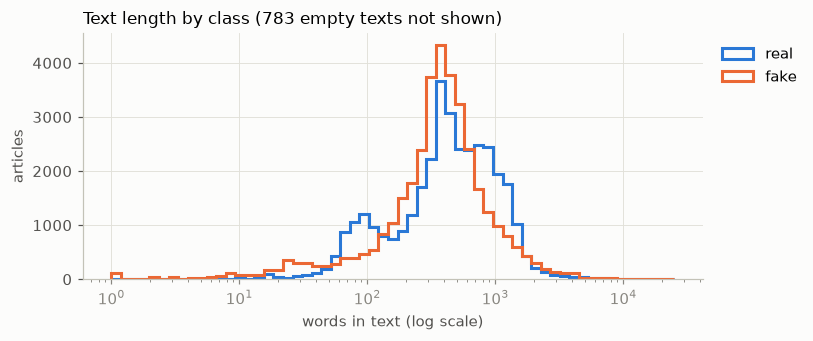

In [6]:
n_words = text.str.count(r"\S+")
title_words = title.str.count(r"\S+")
stats = pd.concat({"text words": n_words.groupby(labels).describe(percentiles=[0.05, 0.5, 0.95]),
                   "title words": title_words.groupby(labels).describe(percentiles=[0.05, 0.5, 0.95])})
display(stats.rename(index={0: "real", 1: "fake"}).round(0))

fig, ax = plt.subplots(figsize=(7.5, 3.2))
bins = np.logspace(0, 4.4, 60)
for y, color, name in ((0, REAL, "real"), (1, FAKE, "fake")):
    ax.hist(n_words[(labels == y) & (n_words > 0)], bins=bins, histtype="step", linewidth=2, color=color, label=name)
ax.set(xscale="log", xlabel="words in text (log scale)", ylabel="articles",
       title=f"Text length by class ({(n_words == 0).sum():,} empty texts not shown)")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1.0))
save(fig, "raw_text_length")
plt.show()

The medians are similar, but the shapes differ: fake articles include many very short texts (teasers,
stubs), real ones have a second peak around 80–100 words (short wire items) and more articles near 1,000 words.
Fake titles are longer (median 13 vs 11 words).

## 6. Exact duplicates

In [7]:
nonempty = text.str.strip().ne("")  # blank texts are not counted as duplicates of each other
display(class_table({
    "duplicate (title, text) rows": per_class(raw.duplicated(["title", "text"], keep="first"), labels),
    "duplicate text rows (non-blank)": per_class(nonempty & text.duplicated(keep="first"), labels),
}))
copies = text[nonempty].value_counts()
copies = copies[copies > 1]
print(f"{len(copies):,} texts occur more than once; the most repeated one occurs {copies.max()} times.")
print(f"identical texts (without title) carrying both labels: {raw[nonempty].groupby(text[nonempty])['label'].nunique().gt(1).sum()}")

,real,fake,share_fake
"duplicate (title, text) rows",237,8219,0.972
duplicate text rows (non-blank),407,8229,0.953


7,729 texts occur more than once; the most repeated one occurs 58 times.


identical texts (without title) carrying both labels: 0


Around 8,500 rows are exact copies of another row, almost all fake. If one copy lands in training and another
in test, the test score is inflated for free. Exact copies are only the most obvious case; **near**-duplicates (the
same story with small edits) are what the MinHash/LSH part of the project measures.

## 7. Titles

In [8]:
upper_share = title.map(lambda s: sum(c.isupper() for c in s) / max(1, sum(c.isalpha() for c in s)))
prefix = title.map(normalize).str.extract(r"^([A-Za-z][A-Za-z' ]{0,24}?)\s*:\s")[0]
class_table({
    "title mostly in capitals (> 80% of letters)": per_class(upper_share > 0.8, labels),
    "title has a tag in brackets, e.g. '(VIDEO)'": per_class(title.str.contains(r"[\[(][A-Z][A-Z /]+[\])]"), labels),
    "title starts with 'Something:' (label or subject)": per_class(prefix.notna(), labels),
})

,real,fake,share_fake
title mostly in capitals (> 80% of letters),2,1042,0.998
"title has a tag in brackets, e.g. '(VIDEO)'",1,6701,1.000
title starts with 'Something:' (label or subject),3573,6900,0.659


In [9]:
tab = pd.DataFrame({"prefix": prefix, "label": labels}).dropna().groupby("prefix")["label"].agg(titles="size", fake="sum")
tab["real"] = tab.titles - tab.fake
tab["share_fake"] = (tab.fake / tab.titles).round(3)
tab[tab.titles >= 25].sort_values("titles", ascending=False)[["titles", "real", "fake", "share_fake"]].head(20)

,titles,real,fake,share_fake
prefix,,,,
WATCH,1230,24,1206,0.980
BREAKING,798,0,798,1.000
Factbox,407,407,0,0.000
Exclusive,229,221,8,0.035
Re,161,0,161,1.000
Report,139,110,29,0.209
JUST IN,106,0,106,1.000
Trump,96,66,30,0.312
REPORT,75,3,72,0.960


Fake titles are often written in capitals and start with editorial labels such as "BREAKING:" or "WATCH:";
real ones use the outlets' product labels ("Factbox:", "Exclusive:", "Review:"). Subjects ("Trump:") are mixed.
The cleaning keeps these labels as part of the published headline (decision G8 in notebook 02); the shared
`content` column is lower-cased, so capitalization itself does not reach the models that use it.

## 8. Vocabulary

How many articles of each class contain each word (English stop words left out, words in at least 500
articles). Counting only.

In [10]:
cv = CountVectorizer(stop_words="english", min_df=500, binary=True, dtype=np.int32)
X = cv.fit_transform(text)
fake_docs = np.asarray(X[(labels == 1).to_numpy()].sum(0)).ravel()
real_docs = np.asarray(X[(labels == 0).to_numpy()].sum(0)).ravel()
vocab = pd.DataFrame({"word": cv.get_feature_names_out(), "real": real_docs, "fake": fake_docs})
vocab["articles"] = vocab.real + vocab.fake
vocab["share_fake"] = (vocab.fake / vocab.articles).round(3)
del X
print(f"{len(vocab):,} words occur in at least 500 articles")
display(Markdown("**Words most specific to one class** (among those in ≥ 500 articles)"))
pd.concat({"most real-specific": vocab.nsmallest(15, "share_fake")[["word", "articles", "share_fake"]].reset_index(drop=True),
           "most fake-specific": vocab.nlargest(15, "share_fake")[["word", "articles", "share_fake"]].reset_index(drop=True)}, axis=1)

4,916 words occur in at least 500 articles


**Words most specific to one class** (among those in ≥ 500 articles)

most real-specific                     most fake-specific                    
                 word articles share_fake               word articles share_fake
0             reuters    22285      0.029             21wire     1088      1.000
1              macron      549      0.058       filessupport      594      1.000
2            overhaul      950      0.068             flickr      709      0.997
3                2019      718      0.086         screengrab      598      0.997
4            emmanuel      584      0.087              getty     4211      0.996
5             beijing     1388      0.093               http      716      0.994
6             jinping      697      0.093         screenshot     1111      0.982
7              beirut      552      0.105           featured     8989      0.952
8           pyongyang      804      0.106                www     1407      0.951
9              mattis      579      0.114                 ny      553      0.942
10                 xi      743      0.118                ass      747      0.934
11            theresa      884      0.124              https     4160      0.928
12             ankara      641      0.126          hilarious      531      0.927
13           contests      593      0.135               shit      641      0.916
14          tillerson     1103      0.135               rant      502      0.912

Three kinds of words appear:

- **Markers of the source or the scraping**, not about the news at all: "reuters" (dateline), "21wire" and
  "filessupport" (21st Century Wire boilerplate), "flickr", "getty", "screengrab", "screenshot", "featured" (image
  credits), "http", "https", "www" (links).
- **Topic and time:** Macron, Beijing, Xi Jinping, Pyongyang, Tillerson, Mattis: world news of 2017, mostly in the
  real (Reuters) part.
- **Style:** informal and emotional words ("hilarious", "rant", swear words) in fake articles.

Separating the first kind (to be removed) from the other two (kept) is what notebook 02 does.

## 9. Language

In [11]:
non_english = text.map(normalize).map(is_non_english)
display(class_table({"not English": per_class(non_english, labels)}))
raw.loc[non_english, ["doc_id", "label", "text"]].sample(6, random_state=1).assign(text=lambda d: d.text.str[:110])

,real,fake,share_fake
not English,1,463,0.998


,doc_id,label,text
32465,32465,1,47 На 101 году жизни скончался старейший член японской императорской семьи принц Микаса — дядя правящего импе
36097,36097,1,"Политика \nДмитрий Анатольевич Медведев знаком российскому обществу не как целомудренный политик, а как человек"
67577,67577,0,Les voix des femmes musulmanes ont été quasiment noyées par le débat agité sur l’interdiction de se baigner en
37388,37388,1,"Los periodistas de La Sexta cobrarán por “zascas” SI EL ""ZASCA"" SE CONVIERTE EN ""MEME"", EL REDACTOR OBTENDRÁ C"
10457,10457,1,فضيحة جنسية تهز أحد أشهر قارئي القرآن وتحرج سلطات إيران \nتاريخ النشر: 26.10.2016 | 15:35 GMT | أحد أشهر قارئي
39145,39145,1,Von wegen Staatsbesuch: Barack Obama ist offenbar auf Wohnungssuche Berlin (dpo) - Plant da jemand einen Umz


A few hundred articles are in Spanish, French, German, Russian, Arabic and other languages, almost all of them
fake. (The detection rule is described in notebook 02, section 6.)

## 10. Time

The dataset has no date column, but articles mention years. Share of articles per class that mention each year:

label,real,fake
2014,0.105,0.062
2015,0.125,0.079
2016,0.151,0.273
2017,0.063,0.066
2018,0.045,0.010


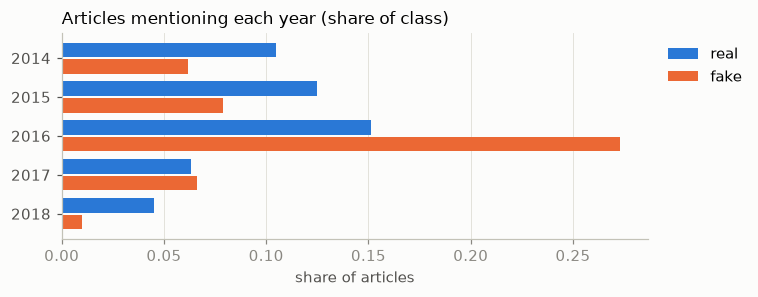

In [12]:
years = pd.DataFrame({str(y): text.str.contains(rf"\b{y}\b") for y in range(2014, 2019)})
share = years.groupby(labels).mean().rename(index={0: "real", 1: "fake"}).T.round(3)
display(share)

fig, ax = plt.subplots(figsize=(7, 2.8))
class_bars(ax, share.index, share.real, share.fake, "Articles mentioning each year (share of class)", xlabel="share of articles")
save(fig, "raw_years_mentioned")
plt.show()

Fake articles mention 2016 far more often than real ones (around the US election), while real articles mention
earlier and later years (2014, 2015, 2018) more often. The classes come from partly different **time windows**,
so their topics differ too. That is part of the data, not something cleaning can or should remove; the
cluster-held-out split measures how much it matters.

## 11. What this means for cleaning

| Finding | Consequence (notebook 02) |
|---|---|
| Label 1 = fake (not as documented) | `is_fake` = `label` |
| Outlet signatures (datelines, credits, bylines, boilerplate) are almost perfectly one class | Remove what identifies the outlet or the scraping process |
| Empty texts are all fake | Drop rows whose text is empty after cleaning |
| ~8,500 exact duplicates, almost all fake | Keep one copy (on the cleaned text) |
| Non-English articles are almost all fake | Drop them |
| Style, topic and time differ between classes | Keep: written by the authors; measured by the split regimes |
| Title labels, very short texts | Keep (decisions G8, G7) |